In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_dev = os.path.join(pth_data, 'development', 'modeling')
pth_mod = os.path.join(pth_data, 'features', 'biomart', 'modules')
pth_out = os.path.join(pth, 'figures', 'cancer', 'CCCA')

In [3]:
adata_dev = sc.read_h5ad(os.path.join(pth_dev, 'spectrum.h5ad'))
adata = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata

AnnData object with n_obs × n_vars = 1406087 × 510
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [4]:
mod_fn = sorted(glob.glob(os.path.join(pth_mod, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
mod_dict = {get_name(fn) : pd.read_csv(fn) for fn in mod_fn}

# module signatures
for mod, df_mod in mod_dict.items():
    if mod != 'ref':
        print(mod)
        g = df_mod.hsapiens.copy()
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = mod,
                              ctrl_as_ref = False,
                              random_state = 1234)
            adata.obs.loc[msk, mod] = adata_group.obs[mod]

adata.obsm['X_spectrum'] = adata.obs[['late', 'early']].values

early
late


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


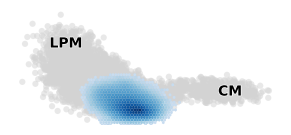

In [13]:
nx, w, h = 100, 3.5, 1.5
fig, ax = plt.subplots(1, 1, figsize = (w, h))
sc.pl.embedding(adata_dev, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
ar = (xlim[1] - xlim[0]) / (ylim[1] - ylim[0])
ny = int((nx / np.sqrt(3)) * (h / w) * ar)
hb = ax.hexbin(adata.obs.late, adata.obs.early, gridsize = [nx, ny],
               extent = [*xlim, *ylim], bins = 'log', mincnt = 45,
               vmin = 5, cmap = 'Blues', linewidths = 0)
scf.pl.milestones(adata_dev, basis = 'spectrum', annotate = True,
                  alpha = 0, show = False, ax = ax)
ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_title('')
fn = os.path.join(pth_out, 'spectrum.pdf')
plt.savefig(fn, bbox_inches = 'tight')